In [1]:
from algo.no_cover import get_covers, get_leaf_node_cover, covered_nodes, get_cover_layer_top_down
import wn
import numpy as np
import seaborn as sns
from algo import utils
from matplotlib import pyplot as plt


In [4]:
wordnet_name = "omw-subset-en"
wordnet = wn.Wordnet(wordnet_name)
leaves = utils.all_leaves(wordnet)

per_layer = True

In [5]:
covers = get_covers(wordnet, per_layer=per_layer)

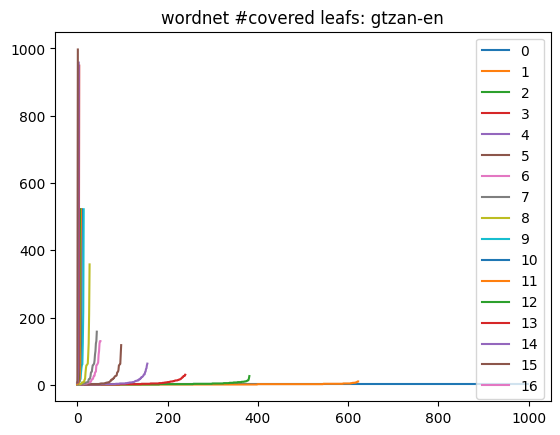

In [ ]:
for i, cover in covers.items():
    lens = list(map(lambda x: len(covered_nodes(frozenset({x,}), leaves)), list(cover)))
    sns.lineplot(np.sort(lens), label=i)
    plt.title(f"wordnet #covered leafs: {wordnet_name}")

In [6]:
for i, cover in covers.items():
    lens = list(map(lambda x: len(covered_nodes(frozenset({x,}))), list(cover)))
    sns.lineplot(np.sort(lens), label=i)
    plt.title(f"wordnet #covered nodes: {wordnet_name}")

AttributeError: 'list' object has no attribute 'items'

In [7]:
for i, cover in covers.items():
    lens = list(map(lambda x: len(covered_nodes(frozenset({x,}), leaves)), list(cover)))
    print(i, len(lens))
    print(lens)
    if i == 0:
        binwidth = None
    else:
        binwidth = 1
    sns.histplot(lens, label=i, binwidth=binwidth)
    plt.title(f"wordnet: {wordnet_name}")
    plt.show()

AttributeError: 'list' object has no attribute 'items'

In [8]:
for i, cover in covers.items():
    lens = list(map(lambda x: len(covered_nodes(frozenset({x,}))), list(cover)))
    print(i, len(lens), np.array(lens).mean())
    print(lens)
    if i == 0:
        binwidth = None
    else:
        binwidth = 1
    sns.histplot(lens, label=i, binwidth=binwidth)
    plt.title(f"wordnet: {wordnet_name}")
    plt.show()

AttributeError: 'list' object has no attribute 'items'

In [9]:
root = wn.taxonomy.roots(wordnet)[0]

len(leaves) / len(covered_nodes(frozenset({root,})))

0.5376344086021505

In [10]:
wordnets = [
    "omw-subset-en",
    "dbpedia14-en",
    "gtzan-en"
]

for wordnet_name in wordnets:
    wordnet = wn.Wordnet(wordnet_name)
    leaves = utils.all_leaves(wordnet)
    root = wn.taxonomy.roots(wordnet)[0]
    print(wordnet_name, len(leaves), len(covered_nodes(frozenset({root,}))))

omw-subset-en 1000 1860
dbpedia14-en 14 25
gtzan-en 10 15


In [ ]:
for wordnet_name in wordnets:
    wordnet = wn.Wordnet(wordnet_name)
    leaves = utils.all_leaves(wordnet)
    covers = get_covers(wordnet, per_layer=(wordnet_name != "gtzan-en"))
    print(wordnet_name, len(covers))
    n_covereds = []
    results = []
    for c_id, cover in enumerate(covers):
        c_result = np.array([len(covered_nodes(frozenset({n,}), leaves)) for n in cover if len(n.hyponyms()) > 1])
        n_covereds.append(c_result)
        # print(c_id, c_result)
        if not np.isnan(c_result.mean()):
            results.append(c_result.mean())
    print()
    print(utils.flatten(n_covereds))
    print(np.median(results), 1/np.median(results), np.mean(results), 1/np.mean(results), 1/np.mean(utils.flatten(n_covereds)), 1/np.median(utils.flatten(n_covereds)))
    print()
    print()

omw-subset-en 17

[np.int64(2), np.int64(3), np.int64(3), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(4), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(3), np.int64(2), np.int64(2), np.int64(6), np.int64(2), np.int64(2), np.int64(3), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(7), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(3), np.int64(6), np.int64(3), np.int64(3), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(5), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(10), np.int64(2), np.int64(4), np.int64(3), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(5), np.int64(4), np.int64(2), np.int64(3), np.int64(6), np.int64(2), np.in

/var/folders/74/vwtt1gl561g84w722clplwrr0000gn/T/ipykernel_25508/1417305882.py:12: RuntimeWarning: Mean of empty slice.
  if not np.isnan(c_result.mean()):
/Users/floris/Documents/projects/hierarchical-conformal-prediction/.venv/lib/python3.10/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [23]:
for wordnet_name in wordnets:
    wordnet = wn.Wordnet(wordnet_name)
    leaves = utils.all_leaves(wordnet)
    nodes = set(wordnet.synsets(pos="n")) - leaves
    print(nodes)
    c_result = np.array([len(covered_nodes(frozenset({n,}), leaves)) for n in nodes if len(n.hyponyms()) > 1])
    print()
    print(np.median(c_result), 1/np.median(c_result), np.mean(c_result), 1/np.mean(c_result))
    print()
    print()

{Synset('omw-subset-en-01692864-n'), Synset('omw-subset-en-02093056-n'), Synset('omw-subset-en-07810907-n'), Synset('omw-subset-en-01802721-n'), Synset('omw-subset-en-03791235-n'), Synset('omw-subset-en-04341686-n'), Synset('omw-subset-en-02106966-n'), Synset('omw-subset-en-03277771-n'), Synset('omw-subset-en-03603722-n'), Synset('omw-subset-en-09366017-n'), Synset('omw-subset-en-10439851-n'), Synset('omw-subset-en-03309808-n'), Synset('omw-subset-en-09214581-n'), Synset('omw-subset-en-01674216-n'), Synset('omw-subset-en-01983048-n'), Synset('omw-subset-en-04161981-n'), Synset('omw-subset-en-04199027-n'), Synset('omw-subset-en-03536348-n'), Synset('omw-subset-en-04187547-n'), Synset('omw-subset-en-02095727-n'), Synset('omw-subset-en-02507649-n'), Synset('omw-subset-en-02120997-n'), Synset('omw-subset-en-02022684-n'), Synset('omw-subset-en-03015254-n'), Synset('omw-subset-en-02014941-n'), Synset('omw-subset-en-01700470-n'), Synset('omw-subset-en-03101986-n'), Synset('omw-subset-en-01886

In [ ]:
np.median(utils.flatten(n_covereds))

In [ ]:
(1/200)/2, (1/10)/2, (1-1/14)/2

In [ ]:
for c_id, cover in covers.items():
    print(c_id, np.array([len(n.hyponyms()) for n in cover if len(n.hyponyms()) > 1]).mean())


In [ ]:
for i, cover in enumerate(covers):
    node_coverages = map(len, map(covered_nodes, list(covers)))

In [ ]:
1 - 1000 / 1400

In [ ]:
sns.histplot(np.array([wn.taxonomy.max_depth(n) for n in leaves]), binwidth=1)

In [ ]:
covers

In [ ]:
len(synsets)